# M1 - Student C: Matching-accuracy + speed protocol
Project 26: compact learned descriptor vs SIFT / ORB

My task in M1 (from the project catalog): **define the matching-accuracy and speed protocol**, i.e. the rules every
method (SIFT, ORB and later our CNN) is tested with, so the comparison is fair.

What I do in this notebook:
1. load HPatches (image pairs + the true homography between them)
2. write the matching and the accuracy metrics (MMA and homography accuracy)
3. test the metric code on cases where I know the right answer
4. write the protocol table for the report
5. show the metrics on one real image pair (SIFT and ORB)
6. define the speed rule and measure SIFT / ORB speed with it

## 0. Setup

In [1]:
import os, glob, shutil, zipfile, time
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

SEED = 42
rng = np.random.default_rng(SEED)

# outputs go to our shared drive folder (local folders if not on colab)
try:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT = "/content/drive/MyDrive/DIP_P26"
    ZIP_DIR = OUT + "/data"          # where we keep the hpatches zip
    DATA = "/content/data"           # colab local disk (much faster than drive)
except ImportError:
    OUT, ZIP_DIR, DATA = "outputs", "data", "local_data"
for d in ["tables", "figures", "results"]:
    os.makedirs(f"{OUT}/{d}", exist_ok=True)
os.makedirs(DATA, exist_ok=True)
print("opencv", cv2.__version__)

Mounted at /content/drive
opencv 4.14.0


## 1. Load HPatches
HPatches has 116 folders (sequences). Each one has 6 images `1.ppm ... 6.ppm` and 5 text files `H_1_2 ... H_1_6`.
`H_1_i` is the **true homography**: a 3x3 matrix that tells where every pixel of image 1 is in image i.
Folders starting with `i_` change the lighting, folders starting with `v_` change the viewpoint.

Like the D2-Net paper we skip 8 very large sequences, so we use **108 sequences** (52 `i_` + 56 `v_`), and match image 1
with images 2-6, giving **540 image pairs**.

In [2]:
def find_seq_folders():
    # all i_* folders on the local disk, ignoring the junk __MACOSX folder that mac zips add
    found = glob.glob(f"{DATA}/**/i_*", recursive=True)
    return sorted(f for f in found if "__MACOSX" not in f and "synthetic" not in f)

# copy the zip from drive and unzip it on the local disk (only the first time in a session)
if not find_seq_folders():
    zips = [z for z in glob.glob(f"{ZIP_DIR}/*") if "hpatches" in z.lower() and z.endswith(".zip")]
    print("unzipping", zips[0])
    shutil.copy(zips[0], DATA)
    with zipfile.ZipFile(os.path.join(DATA, os.path.basename(zips[0]))) as z:
        z.extractall(DATA)

# the folder that holds all the i_* / v_* folders
first = find_seq_folders()[0]
HP_ROOT = os.path.dirname(first)

SKIP = ["i_contruction", "i_crownnight", "i_dc", "i_pencils", "i_whitebuilding",
        "v_artisans", "v_astronautis", "v_talent"]
seqs = sorted(d for d in glob.glob(f"{HP_ROOT}/[iv]_*") if os.path.basename(d) not in SKIP)
n_i = sum(os.path.basename(s).startswith("i_") for s in seqs)
print(len(seqs), "sequences:", n_i, "illumination,", len(seqs) - n_i, "viewpoint ->", 5 * len(seqs), "pairs")

def load_seq(folder):
    # 6 grayscale images + the 5 true homographies (image 1 -> image i)
    imgs = [cv2.imread(f"{folder}/{i}.ppm", cv2.IMREAD_GRAYSCALE) for i in range(1, 7)]
    Hs = {i: np.loadtxt(f"{folder}/H_1_{i}") for i in range(2, 7)}
    return imgs, Hs

unzipping /content/drive/MyDrive/DIP_P26/data/hpatches-sequences-release.zip
108 sequences: 52 illumination, 56 viewpoint -> 540 pairs


## 2. Matching + accuracy metrics
**Matching rule: mutual nearest neighbour (MNN).** Point a in image 1 and point b in image 2 are a match only if b is the
closest descriptor to a **and** a is the closest descriptor to b. It has no threshold to tune, so no method gets an unfair advantage.
Float descriptors (SIFT, our CNN) use L2 distance, binary ones (ORB) use Hamming distance.

**MMA@t (mean matching accuracy):** move every matched point of image 1 with the true homography. If it lands within
`t` pixels of its partner in image 2, the match is correct. MMA@t = correct / all matches, averaged over the pairs, for t = 1...10 px.

**H-acc@t (homography accuracy):** use the matches to estimate the homography with RANSAC (3 px). Move the 4 image corners
with the estimated and with the true homography. If the average corner distance is <= t pixels, the pair counts as correct.
H-acc@t = fraction of correct pairs, for t = 1, 3, 5 px.

In [3]:
# =====================================================================
# 1) MATCHING: pair up descriptors from image 1 and image 2
# =====================================================================
def match_mnn(des1, des2, binary=False):
    # des1 = descriptors of image 1 (one row per keypoint), des2 = same for image 2
    # binary=True for ORB (bits), False for SIFT / our CNN (float numbers)

    # if one image has no descriptors at all, there is nothing to match:
    # return an empty array with 2 columns (index in image 1, index in image 2)
    if des1 is None or des2 is None or len(des1) == 0 or len(des2) == 0:
        return np.zeros((0, 2), int)

    # choose how "distance between two fingerprints" is measured:
    # Hamming = number of different bits (for ORB), L2 = normal straight-line distance (for SIFT / CNN)
    norm = cv2.NORM_HAMMING if binary else cv2.NORM_L2

    # BFMatcher = brute force: compares every descriptor of image 1 with every descriptor of image 2
    # crossCheck=True keeps a pair (a, b) only if b is a's closest AND a is b's closest
    # (this is "mutual nearest neighbour"); .match returns a list of match objects
    ms = cv2.BFMatcher(norm, crossCheck=True).match(des1, des2)

    # each match object has queryIdx (keypoint number in image 1) and trainIdx (keypoint number in image 2)
    # we turn the list into an (N, 2) array; reshape(-1, 2) keeps the shape right even if N = 0
    return np.array([[m.queryIdx, m.trainIdx] for m in ms], int).reshape(-1, 2)


# =====================================================================
# 2) MOVE POINTS WITH A HOMOGRAPHY (where does a point of image 1 land in image 2?)
# =====================================================================
def warp_points(pts, H):
    # pts = (N, 2) array of (x, y) points, H = 3x3 homography matrix

    # a homography works on 3 numbers per point, so (x, y) becomes (x, y, 1)
    # ("homogeneous coordinates"); then multiply every point by H at once
    # (pts_h @ H.T is the same as doing H @ [x, y, 1] for each point)
    p = np.hstack([pts, np.ones((len(pts), 1))]) @ H.T

    # the result is (x', y', w'); the real image position is (x'/w', y'/w')
    # dividing by the 3rd number is what makes perspective (far things look smaller) work
    return p[:, :2] / p[:, 2:]


# =====================================================================
# 3) MMA@t: what fraction of the matches are correct (within t pixels)
# =====================================================================
def mma(p1, p2, H, t):
    # p1 = matched points in image 1, p2 = their partners in image 2 (same order)
    # H = TRUE homography from the dataset, t = allowed error in pixels

    # no matches at all -> accuracy is 0 (avoid dividing by zero)
    if len(p1) == 0:
        return 0.0

    # move each point of image 1 to where it REALLY is in image 2 (using the true H),
    # then measure the pixel distance to the point the matcher paired it with
    err = np.linalg.norm(warp_points(p1, H) - p2, axis=1)

    # (err <= t) is True/False per match; .mean() of True/False = fraction of True
    # e.g. 70 correct out of 100 matches -> 0.70
    return float((err <= t).mean())


# =====================================================================
# 4) CORNER ERROR: how wrong is an estimated homography (in pixels)
# =====================================================================
def corner_error(H_est, H_true, w, h):
    # H_est = homography we estimated from our matches, H_true = the correct one
    # w, h = image width and height

    # if RANSAC could not estimate any homography, the error is "infinite" (always counts as a fail)
    if H_est is None:
        return np.inf

    # the 4 corners of image 1: top-left, top-right, bottom-right, bottom-left
    corners = np.array([[0, 0], [w - 1, 0], [w - 1, h - 1], [0, h - 1]], float)

    # move the 4 corners with our estimate and with the true H,
    # measure how far apart each corner pair is, and take the average of the 4 distances
    # (0 px = perfect estimate; a few px = small mistake; hundreds = completely wrong)
    return float(np.linalg.norm(warp_points(corners, H_est) - warp_points(corners, H_true), axis=1).mean())


# =====================================================================
# 5) ESTIMATE A HOMOGRAPHY FROM MATCHES WITH RANSAC
# =====================================================================
def estimate_h(p1, p2):
    # p1, p2 = matched points (some correct, some wrong)

    # a homography has 8 unknowns, every match gives 2 equations -> need at least 4 matches
    if len(p1) < 4:
        return None

    # RANSAC picks random groups of 4 matches, so we fix OpenCV's random seed
    # -> running the notebook again gives exactly the same result
    cv2.setRNGSeed(SEED)

    # RANSAC: try many random 4-match groups, build a homography from each,
    # count how many other matches agree with it within 3.0 pixels ("inliers"),
    # keep the homography with the most inliers (so wrong matches get ignored)
    # maxIters=5000 = try at most 5000 groups; confidence=0.999 = stop early when 99.9% sure
    # the second output is the inlier mask, which we don't need here (_)
    H, _ = cv2.findHomography(p1, p2, cv2.RANSAC, 3.0, maxIters=5000, confidence=0.999)

    # H is a 3x3 matrix, or None if OpenCV failed
    return H


# =====================================================================
# 6) ALL METRICS FOR ONE IMAGE PAIR
# =====================================================================
def evaluate_pair(kp1, des1, kp2, des2, H_true, img_shape, binary=False):
    # kp1/kp2 = keypoints (positions) of image 1 and 2, des1/des2 = their descriptors
    # H_true = true homography image 1 -> image 2, img_shape = (height, width) of image 1

    # step 1: match the descriptors -> (N, 2) array of index pairs
    m = match_mnn(des1, des2, binary)

    # step 2: turn the index pairs into pixel positions
    # m[:, 0] = indices into image 1's keypoints, .pt = (x, y) of that keypoint
    p1 = np.array([kp1[i].pt for i in m[:, 0]]).reshape(-1, 2)
    # m[:, 1] = indices into image 2's keypoints; p2[k] is the partner of p1[k]
    p2 = np.array([kp2[j].pt for j in m[:, 1]]).reshape(-1, 2)

    # numpy image shape is (rows, columns) = (height, width)
    h, w = img_shape

    # step 3: estimate the homography from the matches and measure its corner error
    cerr = corner_error(estimate_h(p1, p2), H_true, w, h)

    # step 4: collect all results in one dictionary, starting with the number of matches
    res = {"matches": len(m)}

    # MMA at 1, 3, 5 and 10 pixels (how many matches are correct at each tolerance)
    for t in [1, 3, 5, 10]:
        res[f"MMA@{t}"] = mma(p1, p2, H_true, t)

    # homography accuracy at 1, 3 and 5 pixels: 1.0 if the corner error is small enough, else 0.0
    # (averaging this 0/1 value over all 540 pairs later gives the H-acc percentage)
    for t in [1, 3, 5]:
        res[f"H-acc@{t}"] = float(cerr <= t)

    # also keep the raw corner error (useful to look at failures)
    res["corner_err"] = cerr

    # one dictionary per image pair, which becomes one row of the results table
    return res

## 3. Testing the metric code (on a real HPatches pair)

> Add blockquote


Before anyone uses these functions for real numbers, I check them on a real HPatches pair (image 1 -> image 4) with its real
homography. The trick: **I make the matches myself** from the real keypoints and their true positions, so I know exactly what
each metric must return. Each test explains what it asserts, how, and why. Every line should print OK. If one fails,
there is a bug.

In [4]:
# =====================================================================================
# TESTING THE METRIC CODE ON A REAL HPATCHES PAIR
# Idea: I use a real image pair and its real homography, but I make the matches MYSELF.
# Because I make them, I know exactly what every metric should return. If a function
# returns something else, it has a bug.
# =====================================================================================

# ---------- the real data used by all tests ----------
# a viewpoint sequence (v_*): the camera moves, so the homography is not trivial
folder = [s for s in seqs if os.path.basename(s).startswith("v_")][0]
imgs, Hs = load_seq(folder)
img1, img4 = imgs[0], imgs[3]
# H = the TRUE homography from the dataset file H_1_4 (image 1 -> image 4)
H = Hs[4]
h4, w4 = img4.shape

# real SIFT keypoint positions in image 1 (only the positions are used, not SIFT's descriptors)
pts1 = np.array([k.pt for k in cv2.SIFT_create(1000).detect(img1, None)])
# where each of those points REALLY is in image 4, using OpenCV's own function (not ours),
# so the "true answer" does not depend on the code we are testing
pts4 = cv2.perspectiveTransform(pts1.reshape(-1, 1, 2), H).reshape(-1, 2)
# keep only points that are still inside image 4 (the camera moved, some fall outside)
inside = (pts4[:, 0] >= 0) & (pts4[:, 0] < w4) & (pts4[:, 1] >= 0) & (pts4[:, 1] < h4)
pts1, pts4 = pts1[inside], pts4[inside]
n = len(pts1)

# helper: turn (x, y) arrays into OpenCV keypoints (evaluate_pair expects keypoints)
def to_kps(pts):
    return [cv2.KeyPoint(float(x), float(y), 5) for x, y in pts]

# "fake perfect descriptors": point i gets row i of the identity matrix.
# Every descriptor is at distance 0 from its own copy and distance 1.41 from all others,
# so the matcher MUST pair point i of image 1 with point i of image 4.
# This lets me decide the matches myself.
des = np.eye(n, dtype=np.float32)
print(f"{os.path.basename(folder)}: image 1 -> image 4, {n} real keypoints that stay inside image 4\n")


# ---------- TEST 1: warp_points is correct ----------
# ASSERTS: our warp_points gives the same positions as OpenCV's cv2.perspectiveTransform
#          on the real homography (difference below 0.000001 px).
# HOW:     move the same real points with both functions and compare.
# WHY:     every other metric uses warp_points. If it is wrong, all numbers are wrong,
#          and the later tests could even hide the bug (they use warp_points twice).
#          OpenCV is an independent, trusted reference.
ours = warp_points(pts1, H)
assert np.allclose(ours, pts4, atol=1e-6)
print("OK  test 1: warp_points agrees with OpenCV, max difference =", f"{np.abs(ours - pts4).max():.1e}", "px")


# ---------- TEST 2: perfect matches ----------
# ASSERTS: all n points are matched, MMA@1 = 1 (every match within 1 px),
#          H-acc@1 = 1 and the corner error is about 0 px.
# HOW:     every point of image 1 gets its exact true partner in image 4.
# WHY:     the best possible matches must get the best possible score. If perfect input
#          does not give 1.0, the matcher, MMA or homography code is broken.
r = evaluate_pair(to_kps(pts1), des, to_kps(pts4), des, H, img1.shape)
assert r["matches"] == n
assert r["MMA@1"] == 1 and r["H-acc@1"] == 1 and r["corner_err"] < 0.01
print(f"OK  test 2: perfect partners -> {r['matches']} matches, MMA@1 = 1, corner error = {r['corner_err']:.4f} px")


# ---------- TEST 3: exact 4 px error ----------
# ASSERTS: MMA@3 = 0 and MMA@5 = 1; corner error = 4 px; H-acc@3 = 0 and H-acc@5 = 1.
# HOW:     move every true partner exactly 4 px to the right. Every match is then wrong by
#          exactly 4 px, and the homography RANSAC finds is the true one shifted by 4 px,
#          so each corner is off by exactly 4 px.
# WHY:     checks the thresholds are used the right way round (4 > 3 must FAIL, 4 <= 5 must PASS)
#          and that corner_error measures distance in pixels correctly.
r = evaluate_pair(to_kps(pts1), des, to_kps(pts4 + [4, 0]), des, H, img1.shape)
assert r["MMA@3"] == 0 and r["MMA@5"] == 1
assert abs(r["corner_err"] - 4) < 0.01
assert r["H-acc@3"] == 0 and r["H-acc@5"] == 1
print(f"OK  test 3: 4 px shift -> MMA@3 = 0, MMA@5 = 1, corner error = {r['corner_err']:.3f} px")


# ---------- TEST 4: completely wrong matches ----------
# ASSERTS: MMA@10 is close to 0 (below 5%) and the homography fails (H-acc@5 = 0).
# HOW:     shuffle the partners, so point i of image 1 is paired with a random other point.
# WHY:     bad matches must get a bad score. This catches bugs where the metric is
#          always high (for example comparing a point with itself).
shuffled = pts4[np.random.default_rng(SEED).permutation(n)]
r = evaluate_pair(to_kps(pts1), des, to_kps(shuffled), des, H, img1.shape)
assert r["MMA@10"] < 0.05 and r["H-acc@5"] == 0
print(f"OK  test 4: shuffled partners -> MMA@10 = {r['MMA@10']:.3f}, homography failed (corner error {r['corner_err']:.0f} px)")


# ---------- TEST 5: known amount of noise ----------
# ASSERTS: MMA@1, MMA@3 and MMA@10 are close to the values maths predicts, and MMA grows with t.
# HOW:     add random Gaussian noise (sigma = 2 px) to the true partners. For this noise the
#          chance that the error is <= t is exactly  1 - exp(-t^2 / (2 * sigma^2)):
#              t = 1 -> 0.118,   t = 3 -> 0.675,   t = 10 -> 1.000
#          With a few hundred points the measured MMA must be within a few % of these.
# WHY:     the strongest check of MMA: not only "between 0 and 1", but the exact expected value.
sigma = 2.0
noisy = pts4 + np.random.default_rng(SEED).normal(0, sigma, (n, 2))
r = evaluate_pair(to_kps(pts1), des, to_kps(noisy), des, H, img1.shape)
for t in [1, 3, 10]:
    expected = 1 - np.exp(-t**2 / (2 * sigma**2))
    tol = 3 * np.sqrt(expected * (1 - expected) / n) + 0.01      # 3 standard errors of a fraction
    assert abs(r[f"MMA@{t}"] - expected) < tol, (t, r[f"MMA@{t}"], expected)
assert r["MMA@1"] <= r["MMA@3"] <= r["MMA@10"]
print(f"OK  test 5: 2 px noise -> MMA@1 = {r['MMA@1']:.3f} (expected 0.118), "
      f"MMA@3 = {r['MMA@3']:.3f} (expected 0.675), MMA@10 = {r['MMA@10']:.3f} (expected 1.000)")


# ---------- TEST 6: Hamming matching for binary descriptors (ORB) ----------
# ASSERTS: (a) ORB descriptors matched against themselves pair (almost) every point with itself;
#          (b) after flipping 10 of the 256 bits, they still pair with the right original.
# HOW:     real ORB descriptors from image 1 -> match_mnn(..., binary=True) uses Hamming distance
#          (number of different bits). Identical copies have distance 0; 10 flipped bits give
#          distance 10, still far smaller than the distance to other points (~128 bits on average).
#          ("almost": a few textureless keypoints can have identical ORB descriptors, so >= 98%.)
# WHY:     ORB descriptors are bits, not numbers. With the wrong distance (L2 on bytes) the matching
#          is meaningless. This checks that the binary path of match_mnn works.
orb_kps, orb_des = cv2.ORB_create(1000).detectAndCompute(img1, None)
m = match_mnn(orb_des, orb_des, binary=True)
self_rate = (m[:, 0] == m[:, 1]).mean()
assert self_rate >= 0.98
flip = np.zeros(orb_des.shape[1] * 8, np.uint8)
flip[:10] = 1                                                    # 10 bits set to 1
masks = np.array([np.packbits(np.random.default_rng(i).permutation(flip)) for i in range(len(orb_des))])
noisy_des = np.bitwise_xor(orb_des, masks)                       # XOR flips exactly those 10 bits
m = match_mnn(orb_des, noisy_des, binary=True)
noisy_rate = (m[:, 0] == m[:, 1]).mean()
assert noisy_rate >= 0.98
print(f"OK  test 6: ORB/Hamming -> {self_rate:.1%} paired with themselves, {noisy_rate:.1%} still correct after 10 flipped bits")


# ---------- TEST 7: the dataset's homography is correct ----------
# ASSERTS: warping image 1 with the true H lines it up with image 4 better than an H
#          that is only 10 px wrong (smaller mean pixel difference).
# HOW:     cv2.warpPerspective "moves" image 1 into image 4's frame. Compare pixels where they overlap.
# WHY:     all metrics trust H_1_4 as the truth. This checks we loaded the right file in the
#          right direction (image 1 -> image 4, not the inverse). The difference with the true H
#          is not 0: the photos were taken at different moments, so pixels never match exactly.
def mean_diff(H_try):
    warped = cv2.warpPerspective(img1, H_try, (w4, h4))
    overlap = cv2.warpPerspective(np.ones_like(img1), H_try, (w4, h4)) > 0
    return np.abs(warped[overlap].astype(float) - img4[overlap].astype(float)).mean()
d_true = mean_diff(H)
d_wrong = mean_diff(np.array([[1, 0, 10], [0, 1, 0], [0, 0, 1.0]]) @ H)   # true H, then 10 px shift
assert d_true < d_wrong
print(f"OK  test 7: true H aligns the images -> mean pixel difference {d_true:.1f} (true H) vs {d_wrong:.1f} (10 px off)")

print("\nall 7 metric tests passed on real HPatches data")

v_abstract: image 1 -> image 4, 911 real keypoints that stay inside image 4

OK  test 1: warp_points agrees with OpenCV, max difference = 3.4e-13 px
OK  test 2: perfect partners -> 911 matches, MMA@1 = 1, corner error = 0.0000 px
OK  test 3: 4 px shift -> MMA@3 = 0, MMA@5 = 1, corner error = 4.000 px
OK  test 4: shuffled partners -> MMA@10 = 0.007, homography failed (corner error 847 px)
OK  test 5: 2 px noise -> MMA@1 = 0.132 (expected 0.118), MMA@3 = 0.675 (expected 0.675), MMA@10 = 1.000 (expected 1.000)
OK  test 6: ORB/Hamming -> 100.0% paired with themselves, 100.0% still correct after 10 flipped bits
OK  test 7: true H aligns the images -> mean pixel difference 10.8 (true H) vs 23.7 (10 px off)

all 7 metric tests passed on real HPatches data


**Output:** 7 OK lines. Test 5 is the strongest one: with 2 px noise, maths says 11.8% of matches are within 1 px,
67.5% within 3 px and ~100% within 10 px, and our MMA gives (almost) exactly those numbers.
In test 7 the pixel difference with the true H is not 0 on real photos (they were taken at different moments), but it is
smaller than with a homography that is 10 px off.

## 4. Protocol table (for the report)

In [5]:
protocol = pd.DataFrame([
    ["Data", "HPatches, 108 sequences (52 illumination + 56 viewpoint), image 1 vs images 2-6 = 540 pairs, full resolution"],
    ["Keypoints", "up to 2000 per image for every method"],
    ["Matching", "mutual nearest neighbour; L2 for float descriptors, Hamming for binary"],
    ["MMA@t", "fraction of matches with error <= t px under the true homography, t = 1..10 px, averaged over pairs"],
    ["H-acc@t", "RANSAC homography (3 px); correct if mean corner error <= t px, t = 1, 3, 5 px"],
    ["Speed", "time per image (detect + describe), 1 CPU thread, 2 warm-up runs, median of 10 runs, 10 fixed images"],
    ["Memory", "bytes per descriptor"],
    ["Seed", "42 (image selection and RANSAC)"],
], columns=["Item", "Rule"])
display(protocol)

protocol.to_csv(f"{OUT}/results/m1_protocol.csv", index=False)
with open(f"{OUT}/tables/m1_protocol.tex", "w") as f:
    f.write(protocol.to_latex(index=False, column_format="lp{11cm}",
                              caption="Evaluation protocol used for all methods.", label="tab:protocol"))

,Item,Rule
0,Data,"HPatches, 108 sequences (52 illumination + 56 ..."
1,Keypoints,up to 2000 per image for every method
2,Matching,mutual nearest neighbour; L2 for float descrip...
3,MMA@t,fraction of matches with error <= t px under t...
4,H-acc@t,RANSAC homography (3 px); correct if mean corn...
5,Speed,"time per image (detect + describe), 1 CPU thre..."
6,Memory,bytes per descriptor
7,Seed,42 (image selection and RANSAC)


## 5. The metrics on one real pair
SIFT and ORB on one viewpoint sequence (image 1 vs image 4). In the picture, green lines are correct matches (<= 3 px)
and red lines are wrong ones.

In [6]:
folder = [s for s in seqs if os.path.basename(s).startswith("v_")][0]
imgs, Hs = load_seq(folder)
img1, img4 = imgs[0], imgs[3]

sift = cv2.SIFT_create(2000)
orb = cv2.ORB_create(2000)

rows = []
for name, det, binary in [("SIFT", sift, False), ("ORB", orb, True)]:
    k1, d1 = det.detectAndCompute(img1, None)
    k2, d2 = det.detectAndCompute(img4, None)
    r = evaluate_pair(k1, d1, k2, d2, Hs[4], img1.shape, binary)
    rows.append({"method": name, **r})
    if name == "SIFT":
        sift_result = (k1, d1, k2, d2)
example = pd.DataFrame(rows).round(3)
print(os.path.basename(folder), "image 1 vs 4")
display(example)

v_abstract image 1 vs 4


,method,matches,MMA@1,MMA@3,MMA@5,MMA@10,H-acc@1,H-acc@3,H-acc@5,corner_err
0,SIFT,637,0.105,0.322,0.391,0.410,0.0,0.0,1.0,3.461
1,ORB,681,0.142,0.576,0.711,0.756,0.0,1.0,1.0,2.632


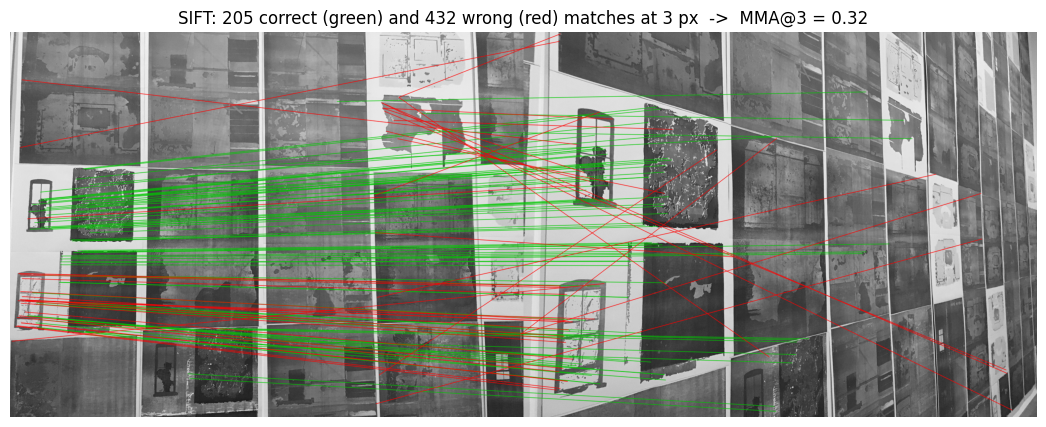

In [8]:
# =====================================================================
# GOAL: draw the two images side by side and connect matched points with lines
#       green line = correct match (lands within 3 px of the true position)
#       red line   = wrong match
#
#   +----------------+----------------+
#   |   image 1      |   image 4      |
#   |    *-----------|------->*       |   green: correct partner
#   |       *--------|--->*           |   red:   wrong partner
#   +----------------+----------------+
# =====================================================================

# take back the SIFT results we saved in the previous cell:
# k1, k2 = keypoints (positions) of image 1 and image 4
# d1, d2 = their SIFT descriptors (128 numbers each)
k1, d1, k2, d2 = sift_result

# match the descriptors (mutual nearest neighbour). m is a table of index pairs:
#   m = [[ 0, 17],     -> keypoint 0 of image 1 is paired with keypoint 17 of image 4
#        [ 5,  3],     -> keypoint 5 of image 1 is paired with keypoint 3 of image 4
#        ...    ]
m = match_mnn(d1, d2)

# turn the index pairs into pixel positions (x, y)
# column 0 of m = indices into image 1, .pt gives the (x, y) of that keypoint
p1 = np.array([k1[i].pt for i in m[:, 0]])
# column 1 of m = indices into image 4; p2[k] is the partner of p1[k]
p2 = np.array([k2[j].pt for j in m[:, 1]])

# how wrong is each match? (in pixels)
#   1) move p1 with the TRUE homography -> where the point REALLY is in image 4
#   2) measure the distance to p2 (where the matcher SAYS it is)
#
#        true position (from H)  o
#                                 \  <- err = this distance
#        matcher's partner p2      *
#
# axis=1 -> one distance per match
err = np.linalg.norm(warp_points(p1, Hs[4]) - p2, axis=1)

# build one wide picture: image 1 on the left, image 4 on the right
# cvtColor GRAY2BGR turns gray images into 3-channel colour images so we can draw coloured lines on them
# np.hstack glues them side by side (horizontally)
#   canvas = [ image 1 | image 4 ]
canvas = np.hstack([cv2.cvtColor(img1, cv2.COLOR_GRAY2BGR), cv2.cvtColor(img4, cv2.COLOR_GRAY2BGR)])

# image 4 starts where image 1 ends, so on the canvas every x of image 4 must be moved right
# by the width of image 1
#   x = 0        x = shift_x
#   |  image 1   |  image 4   |
shift_x = img1.shape[1]

# split the matches into correct and wrong ones using the 3 px rule (the same rule as MMA@3)
# np.where(...)[0] gives the positions (row numbers) where the condition is True
#   err  = [0.4, 12.0, 1.1, 250.3, 2.9]
#   good = [0, 2, 4]   (err <= 3)
#   bad  = [1, 3]      (err > 3)
good, bad = np.where(err <= 3)[0], np.where(err > 3)[0]

# draw the lines: first the correct ones in green, then the wrong ones in red
# we only draw the first 80 good and 40 bad matches, otherwise the picture is a solid block of lines
# colours are (Blue, Green, Red) because OpenCV uses BGR order:
#   (0, 200, 0) = green,   (0, 0, 255) = red
for idx, color in [(good[:80], (0, 200, 0)), (bad[:40], (0, 0, 255))]:
    for i in idx:
        # start of the line: the point in image 1 (pixel positions must be whole numbers -> int)
        a = (int(p1[i][0]), int(p1[i][1]))
        # end of the line: the partner in image 4, moved right by shift_x because image 4
        # sits to the right of image 1 on the canvas
        b = (int(p2[i][0]) + shift_x, int(p2[i][1]))
        # draw the line on the canvas: thickness 1 px, LINE_AA = smooth (anti-aliased) edges
        cv2.line(canvas, a, b, color, 1, cv2.LINE_AA)

# show the picture with matplotlib, 14 x 5 inches so the two images are big enough
plt.figure(figsize=(14, 5))
# matplotlib expects RGB but OpenCV made BGR -> [..., ::-1] reverses the 3 colour channels
# (without this, green stays green but red would show as blue)
plt.imshow(canvas[..., ::-1])
# hide the x/y axis numbers, they are not useful for a picture
plt.axis("off")
# title with the counts; MMA@3 = correct matches / all matches
#   e.g. 600 correct out of 1000 matches -> MMA@3 = 0.60
# (all matches are counted here, even the ones we did not draw)
plt.title(f"SIFT: {len(good)} correct (green) and {len(bad)} wrong (red) matches at 3 px  ->  MMA@3 = {len(good)/len(m):.2f}")
# save the figure into the shared drive folder for the report
# dpi=120 = image resolution, bbox_inches="tight" = cut the empty white border
plt.savefig(f"{OUT}/figures/m1_protocol_example.png", dpi=120, bbox_inches="tight")
# display it in the notebook
plt.show()-

**Output:** the table gives the number of matches, MMA at 1/3/5/10 px and whether the homography was found for each method.
The picture shows what MMA means: MMA@3 is just the share of green lines.

## 6. Speed protocol + SIFT / ORB speed
The timing rule, the same for every method:
- **1 CPU thread** (so a method can't win just by using more cores)
- **2 warm-up runs** first (the first runs are always slower)
- then **10 runs**, keep the **median** (one slow run because of Colab doesn't matter)
- on **10 fixed images** picked with seed 42
- time = detect keypoints + compute descriptors, **2000 keypoints**

In [9]:
cv2.setNumThreads(1)

def time_method(det, img, warmup=2, runs=10):
    for _ in range(warmup):
        det.detectAndCompute(img, None)
    times = []
    for _ in range(runs):
        t0 = time.perf_counter()
        det.detectAndCompute(img, None)
        times.append((time.perf_counter() - t0) * 1000)   # ms
    return np.median(times)

# 10 fixed images (image 1 of 10 random sequences, same every run because of the seed)
pick = np.random.default_rng(SEED).choice(len(seqs), size=min(10, len(seqs)), replace=False)
timing_imgs = [cv2.imread(f"{seqs[k]}/1.ppm", cv2.IMREAD_GRAYSCALE) for k in sorted(pick)]
print("timing images:", [os.path.basename(seqs[k]) for k in sorted(pick)])

speed = []
for name, det, n_bytes in [("SIFT", cv2.SIFT_create(2000), 128 * 4),   # 128 floats x 4 bytes
                           ("ORB", cv2.ORB_create(2000), 32)]:          # 256 bits = 32 bytes
    per_img = [time_method(det, im) for im in timing_imgs]
    speed.append({"method": name,
                  "ms per image (median)": round(float(np.median(per_img)), 1),
                  "min ms": round(min(per_img), 1),
                  "max ms": round(max(per_img), 1),
                  "bytes per descriptor": n_bytes})

cv2.setNumThreads(-1)   # back to normal
speed = pd.DataFrame(speed)
speed["SIFT / method"] = (speed["ms per image (median)"].iloc[0] / speed["ms per image (median)"]).round(1)
display(speed)

speed.to_csv(f"{OUT}/results/m1_timing.csv", index=False)
with open(f"{OUT}/tables/m1_timing.tex", "w") as f:
    f.write(speed.to_latex(index=False, float_format="%.1f",
                           caption="Speed of the classical baselines (1 CPU thread, 2000 keypoints, median of 10 runs on 10 fixed images).",
                           label="tab:timing"))

timing images: ['i_chestnuts', 'i_crownday', 'i_dome', 'i_kurhaus', 'i_table', 'v_calder', 'v_courses', 'v_feast', 'v_posters', 'v_weapons']


,method,ms per image (median),min ms,max ms,bytes per descriptor,SIFT / method
0,SIFT,446.5,172.5,687.0,512,1.0
1,ORB,34.1,23.6,57.7,32,13.1


**Output:** milliseconds per image for SIFT and ORB (median over the 10 images, with min and max to show the spread),
the memory per descriptor, and how many times faster each method is than SIFT. ORB should be much faster and much smaller than SIFT.
Later, our CNN will be timed with the same function and the same 10 images.

## Summary (goes to the M1 report)
- **Protocol** (sec. 3, or an "Evaluation protocol" paragraph in sec. 4): `tables/m1_protocol.tex`
- **Speed baseline numbers**: `tables/m1_timing.tex`, next to Student A's accuracy table. Together they are the
  "SIFT/ORB baseline numbers" deliverable.
- **Figure** (optional): `figures/m1_protocol_example.png` to explain MMA
- The tests in section 3 show the metric code is correct. Keep this notebook with its outputs in the repo.
- Student A uses the same matching (MNN) and metrics, so all numbers in the report follow the same rules.